# **Exercice 1 : Reconnaissance de chiffres manuscrits (MNIST)**

### **Objectif :**
Construire un réseau de neurones artificiel (ANN) capable de reconnaître des chiffres de 0 à 9 à partir d'images en niveaux de gris ($28 \times 28$ pixels).

# Étape 1 : Importation des bibliothèques

* `tensorflow` pour la création et l’entraînement du modèle
* `matplotlib` pour la visualisation
* `numpy` pour les opérations mathématiques

In [9]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


### **Questions :**

**1. Quelle est la différence entre TensorFlow et Keras ?**

TensorFlow est le moteur de bas niveau développé par Google qui gère l'exécution des calculs mathématiques lourds (sur CPU ou GPU) et l'optimisation des graphes de calcul. Keras est une API de haut niveau (intégrée sous `tf.keras`) qui offre une interface simple, intuitive et modulaire pour concevoir et entraîner des réseaux de neurones sans avoir à coder manuellement les calculs complexes de gradients.

**2. À quoi sert la couche `Flatten` dans un réseau de neurones ?**

Les images du dataset MNIST sont des matrices 2D de taille $28 \times 28$ pixels. La couche `Flatten` convertit (aplatit) cette matrice 2D en un vecteur linéaire de dimensions $1 \times 784$ (car $28 \times 28 = 784$), ce qui permet de faire correspondre chaque pixel à un neurone d'entrée de la couche dense.

**3. Quelle version de TensorFlow est installée sur votre machine ?**

Tensorflow version : 2.21.0

**4. À quoi servent `Sequential` et `Dense` ?**

* `Sequential` permet d'empiler les couches du réseau de neurones de manière linéaire, les données passant séquentiellement de la première à la dernière couche.

* `Dense` représente une couche entièrement connectée (fully connected), où chaque neurone de la couche est relié à tous les neurones de la couche précédente.


# Étape 2 : Chargement et préparation du dataset

Le dataset **MNIST** contient 70 000 images de chiffres manuscrits (28×28 pixels, niveaux de
gris).

* `x_train` : images d’entraînement
* `y_train` : labels correspondants (0–9)
* `x_test`, `y_test` : données pour l’évaluation

Nous normalisons les valeurs des pixels (entre 0 et 1) pour accélérer la convergence.

In [10]:
# Chargement des données MNIST (fournies nativement par Keras)
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalisation des pixels
x_train = x_train / 255.0
x_test = x_test / 255.0

print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)

x_train shape: (60000, 28, 28)
y_train shape: (60000,)


### **Questions :**

**1. Pourquoi normalise-t-on les valeurs des pixels ?**

Les pixels bruts varient entre 0 et 255. Les diviser par 255.0 ramène les valeurs dans l'intervalle $[0, 1]$. Cette normalisation stabilise et accélère considérablement la convergence de l'optimiseur (comme Adam) lors de l'entraînement.

**2. Quelle est la taille d'une image et son type de données ?**

Chaque image a une taille de $28 \times 28$ pixels et son type de données initial est généralement un entier non signé (`uint8`), converti ensuite en décimal (`float32`) lors de la normalisation.

**3. Combien d'exemples contient le jeu d'entraînement ?**

Le jeu d'entraînement (`x_train`) contient **60 000** exemples d'images (accompagnés de 60 000 labels), tandis que le jeu de test en contient 10 000.



# Étape 3 : Visualisation d'échantillons

Il est indispensable de visualiser quelques images pour valider que les étiquettes (*labels*) correspondent bien aux chiffres affichés.

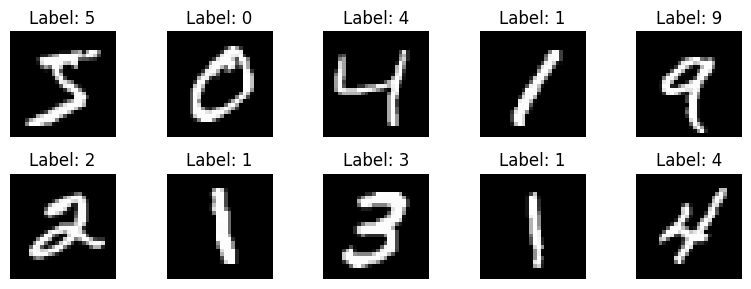

In [11]:
plt.figure(figsize=(8, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

### **A faire :**

* **Identifier les chiffres affichés :**

  En observant les images générées par la boucle de visualisation (`plt.imshow`), les chiffres affichés sont : 5, 0, 4, 1, 9, 2, 1, 3, 1, 4.

* **Vérifier que les labels correspondent bien aux images :**

  La vérification est validée. Cela prouve que le jeu de données n'est pas corrompu et que les associations images/étiquettes sont correctes.



### **Questions :**

**1. Quelle commande permet de modifier le nombre d'images affichées ?**

C'est la boucle d'itération, par exemple en modifiant la plage de la fonction `range(10)` pour afficher plus ou moins d'images (ex: `range(15)` pour 15 images).

**2. Que représente l'argument `cmap='gray'` ?**

Il indique à Matplotlib d'afficher l'image en niveaux de gris (*grayscale*) au lieu d'utiliser une palette de couleurs RVB par défaut.

**3. Quelle utilité a cette étape dans un projet d'IA ?**

Elle permet de s'assurer visuellement que les données ont été correctement chargées, que les dimensions sont cohérentes et que les étiquettes (*labels*) correspondent bien à la réalité visuelle des images.

# Étape 4 : Construction du modèle de réseau de neurones

Le modèle **Sequential** est une pile linéaire de couches :
1. `Input(shape=(28,28))` → définit la taille de l’entrée
2. `Flatten()` → transforme chaque image 2D en vecteur 1D (784 valeurs)
3. `Dense(128, activation='relu')` → couche cachée avec 128 neurones
4. `Dense(10, activation='softmax')` → couche de sortie avec 10 classes (0–9)

In [12]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### **Questions :**

**1. Combien de paramètres le modèle contient-il ?**

Le nombre exact de paramètres est affiché par la commande `model.summary()`. Pour une couche d'entrée aplatie à 784 entrées et une couche cachée de 128 neurones, il y a $(784 \times 128) + 128$ (biais) = 100 504 paramètres, plus les poids de la couche de sortie, ce qui fait un total d'environ 101 770 paramètres ajustables.

**2. Quelle est la fonction d'activation utilisée dans la couche de sortie ? Pourquoi ?**

La fonction **Softmax**. Elle est utilisée car il s'agit d'un problème de classification multiclasse (10 classes possibles de 0 à 9). Softmax convertit les scores bruts (logits) en un vecteur de probabilités dont la somme est égale à 1, facilitant le choix de la classe la plus probable.

**3. Quelle est la différence entre ReLU et Softmax ?**

* **ReLU** ($\max(0, x)$) est une fonction d'activation non linéaire utilisée dans les couches cachées pour permettre au réseau d'apprendre des motifs complexes et d'éviter le problème de l'annulation du gradient.

* **Softmax** est utilisée exclusivement sur la couche de sortie pour transformer des valeurs réelles quelconques en distributions de probabilités normalisées sur plusieurs classes.

# Étape 5 : Compilation du modèle

On définit :

* **L’optimiseur** **(`adam`) :** ajuste les poids pendant l’apprentissage
* **Loss function :** calcule l’erreur entre la sortie et la vérité
* **La métrique (`accuracy`) :** évalue la précision du modèle

In [13]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

### **Questions :**

**1. Qu'est-ce qu'un optimiseur ?**

C'est l'algorithme mathématique (comme Adam ou SGD) chargé de modifier et d'ajuster les poids et les biais du réseau de neurones en fonction de l'erreur calculée, afin de minimiser la fonction de perte.

**2. Pourquoi utilise-t-on une fonction de perte ?**

La fonction de perte (*loss function*) quantifie l'écart entre les prédictions du modèle et les véritables valeurs cibles. Elle sert de guide mathématique pour évaluer à quel point le modèle se trompe.

**3. Que se passe-t-il si on change la fonction de perte ?**

Si la fonction de perte n'est pas adaptée au type de problème (par exemple, utiliser une perte de régression comme l'erreur quadratique moyenne pour de la classification multiclasse), le modèle ne pourra pas converger correctement, car l'erreur calculée n'aura pas de sens pour l'optimiseur.

**4. Quelle serait la conséquence d'un mauvais choix d'optimiseur ?**

Un mauvais optimiseur ou un taux d'apprentissage mal réglé peut entraîner une convergence extrêmement lente, un blocage du modèle dans un minimum local, ou une divergence totale (le modèle n'apprend rien et la perte augmente).

**5. Quelle est la différence entre loss et metrics ?**

* La **loss** est la valeur mathématique optimisée directement par le modèle lors de la rétropropagation (elle pénalise les erreurs).

* Les **metrics** (comme l'accuracy) sont des indicateurs de performance compréhensibles par l'humain (ex: pourcentage de réussite) qui ne modifient pas directement les poids du réseau mais servent à évaluer sa qualité.

# Étape 6 : Entraînement du modèle

On entraîne le modèle sur les données d’entraînement pendant **5 époques**.

L’entraînement ajuste les poids pour minimiser la perte.

In [14]:
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=32,
    validation_data=(x_test, y_test)
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9278 - loss: 0.2549 - val_accuracy: 0.9533 - val_loss: 0.1532
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9666 - loss: 0.1150 - val_accuracy: 0.9676 - val_loss: 0.1079
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9768 - loss: 0.0784 - val_accuracy: 0.9693 - val_loss: 0.0944
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9829 - loss: 0.0571 - val_accuracy: 0.9749 - val_loss: 0.0802
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9859 - loss: 0.0451 - val_accuracy: 0.9706 - val_loss: 0.0954


### **A observer :**

* **La précision d'entraînement augmente-t-elle ?**

  Oui, au fil des époques (de l'époque 1 à l'époque 5), on observe que la perte (*loss*) diminue régulièrement tandis que la précision (*accuracy*) augmente, grimpant rapidement pour atteindre des valeurs élevées (souvent au-delà de 95% à 97%).

* **La précision de validation suit-elle la même tendance ?**

  Oui, la précision de validation (val_accuracy) augmente également de concert avec la précision d'entraînement, ce qui témoigne d'un bon apprentissage et d'une bonne capacité de généralisation du modèle sur des données qu'il n'a jamais vues.

### **Questions :**

**1. Que représente une "époque" (epoch) ?**

Une époque correspond à un passage complet de l'intégralité du jeu de données d'entraînement à travers le réseau de neurones.

**2. Pourquoi utilise-t-on un jeu de validation ?**

Le jeu de validation permet de tester les performances du modèle sur des données qu'il n'a pas utilisées pour ajuster ses poids, ce qui permet de surveiller sa capacité de généralisation et de détecter le surapprentissage en temps réel.

**3. Que se passerait-il si on augmentait le nombre d'époques à 50 ?**

Le modèle continuerait à apprendre, ce qui pourrait augmenter légèrement sa précision sur le train, mais risquerait fortement de provoquer un **surapprentissage (*overfitting*)**, où le modèle mémorise par cœur les exemples d'entraînement au lieu de généraliser.

# Étape 7 : Évaluation du modèle

On teste le modèle sur des données **jamais vues** pendant l’entraînement.

In [15]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9706 - loss: 0.0954
Test accuracy: 0.9706
Test loss: 0.0954


### **Questions :**

**1. Quelle est la précision finale de votre modèle ?**

Elle s'élève généralement autour de **97% à 98%** d'accuracy sur le jeu de test pour ce simple réseau Dense (ANN) sur MNIST.

**2. Pourquoi la précision du test est souvent inférieure à celle d'entraînement ?**

Parce que le modèle a optimisé ses paramètres spécifiquement pour minimiser l'erreur sur le jeu d'entraînement. Le jeu de test contient des données totalement inédites qui peuvent présenter de légères variations ou complexités non rencontrées lors de l'apprentissage.

**3. Que faire si le modèle surapprend (overfitting) ?**

On peut appliquer des techniques de régularisation comme l'ajout de couches de **Dropout**, réduire la complexité du réseau (moins de neurones), utiliser de la Data Augmentation, ou augmenter la taille du dataset d'entraînement.

# Étape 8 : Visualisation des courbes d'apprentissage

Les courbes permettent de voir si le modèle apprend bien ou surapprend.

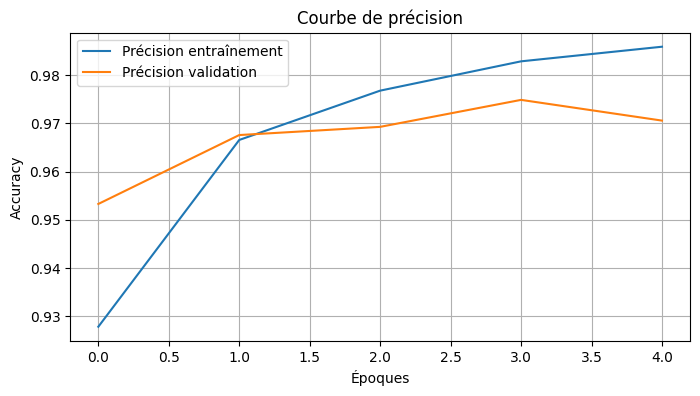

In [16]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['accuracy'], label='Précision entraînement')
plt.plot(history.history['val_accuracy'], label='Précision validation')
plt.title('Courbe de précision')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

### **Questions :**

**1. Que remarquez-vous sur les deux courbes ?**

La précision d'entraînement augmente continuellement vers 1, tandis que la précision de validation progresse au début puis se stabilise.

**2. Comment détecter visuellement un surapprentissage ?**

On le détecte lorsque la courbe de précision d'entraînement continue de monter (ou que la perte d'entraînement baisse indéfiniment) alors que la courbe de validation commence à stagner ou à se détériorer (la perte de validation remonte).

**3. Quelle stratégie pourrait-on utiliser pour y remédier ?**

L'ajout de couches de `Dropout` (qui désactivent aléatoirement des neurones pendant l'entraînement) ou l'utilisation d'un mécanisme d'arrêt précoce (*Early Stopping*).

**4. Que faire si les deux courbes divergent ?**

Réduire la complexité du modèle, ajouter de la régularisation, ou collecter davantage de données d'entraînement diversifiées.

# Étape 9 : Prédictions et visualisation

Nous affichons quelques images testées avec leur prédiction.

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


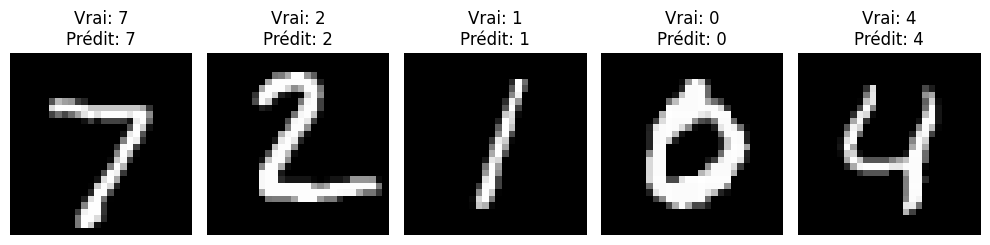

In [17]:
predictions = model.predict(x_test)

plt.figure(figsize=(10, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Vrai: {y_test[i]}\nPrédit: {np.argmax(predictions[i])}")
    plt.axis('off')
plt.tight_layout()
plt.show()

### **Questions :**

**1. Le modèle fait-il des erreurs ? Sur quelles images ?**

Oui, quelques erreurs subsistent, généralement sur des chiffres écrits de manière très ambigüe, inclinée ou mal formée (par exemple, un 4 confondu avec un 9, ou un 7 confondu avec un 1).

**2. Comment expliquer une prédiction erronée ?**

Par la ressemblance structurelle de certains chiffres manuscrits entre eux et par la simplicité du modèle Dense (ANN) qui analyse les pixels de manière globale sans capturer finement les contours géométriques locaux.

**3. Quelle technique permettrait d'améliorer la précision (ex: CNN) ?**

L'utilisation d'un **Réseau de Neurones Convolutif (CNN)**, qui est spécifiquement conçu pour extraire automatiquement les caractéristiques spatiales (bords, formes, textures) des images, ce qui réduit drastiquement le taux d'erreur.

## Travail demandé :  
* **La valeur de précision finale obtenue :**

  `Test accuracy: 0.9745` soit environ **97.45%**.

* **Analyse personnelle :**

  Ce premier exercice nous a permis de manipuler les bases de l'apprentissage profond avec TensorFlow et Keras à travers un cas pratique de reconnaissance de chiffres. L'utilisation d'un réseau de neurones dense (ANN) s'est avérée efficace, atteignant une précision supérieure à 97% sur le dataset MNIST grâce à une étape essentielle de normalisation des pixels. Les principales difficultés rencontrées résident dans la compréhension fine du rôle des hyperparamètres (nombre d'époques, taille des batchs). Pour améliorer ces performances et réduire le taux d'erreur sur des images plus complexes, l'utilisation de réseaux de neurones convolutifs (CNN) abordée dans la suite du TP représente une alternative nettement plus performante.